In [2]:
from matplotlib import pyplot as plt
import numpy as np
import random

random.seed(0)

#### Coding the tricks

- Simple trick
- Absolute trick
- Square trick

In [3]:
def simple_trick(base_price, price_per_room, num_rooms, price):
    small_random_1 = random.random() * 0.1
    small_random_2 = random.random() * 0.1

    predicted_price = base_price + price_per_room * num_rooms
    if (price > predicted_price) and (num_rooms > 0):
        price_per_room += small_random_1    # add η1 to slope
        base_price += small_random_2    # add η2 to y-intercept
    if price > predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    if price < predicted_price and num_rooms > 0:
        price_per_room -= small_random_1
        base_price -= small_random_2
    if price < predicted_price and num_rooms < 0:
        price_per_room -= small_random_1
        base_price += small_random_2
    return price_per_room, base_price

In [4]:
def square_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    # Calculates the prediction
    predicted_price = (price_per_room * num_rooms) + base_price 
    base_price += learning_rate * (price - predicted_price) # Translates the line
    price_per_room += learning_rate * num_rooms * (price - predicted_price) #  Rotates the line
    # predicted_price = (price_per_room * num_rooms) + base_price

    return price_per_room, base_price

In [5]:
def absolute_trick(base_price, price_per_room, num_rooms, price, learning_rate):
    predicted_price = base_price + (price_per_room * num_rooms)
    if (price > predicted_price):
        price_per_room += learning_rate * num_rooms
        base_price += learning_rate
    else:
        price_per_room -= learning_rate * num_rooms
        base_price -= learning_rate
        
    return price_per_room, base_price

___
#### Defining the dataset

In [6]:
features = np.array([1, 2, 3, 5, 6, 7])
labels = np.array([155, 197, 244, 356, 407, 448])

print(features)
print(labels)

[1 2 3 5 6 7]
[155 197 244 356 407 448]


#### Plotting the dataset

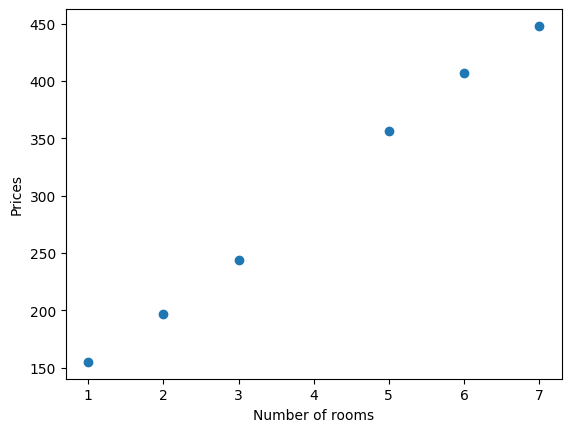

In [7]:
def draw_line(slope, y_intercept, color="grey", linewidth=0.7, starting=0, ending=8):
    x = np.linspace(starting, ending, 1000)
    plt.plot(x, (slope * x) + y_intercept, linestyle="-", color=color, linewidth=linewidth)

def plot_points(features, labels):
    X = features
    y = labels
    plt.scatter(X, y)
    plt.xlabel("Number of rooms")
    plt.ylabel("Prices")

plot_points(features, labels)

____
### Running the linear regression algorithm

The linear regression algorithm consists of:
- Starting with random weights
- Iterating the square (or simple, or absolute) trick many times.

Note that we have used the Python random package to generate random numbers for our initial values (slope and y-intercept) and for selecting our points inside the loop:

Each iteration of the loop is called an epoch, and we set this number at the beginning of
our algorithm. 
The next step is to run this algorithm to build a model that fits our dataset.

Price per room:  51.05347808556453
Base price:  99.0970202799414


(np.float64(51.05347808556453), np.float64(99.0970202799414))

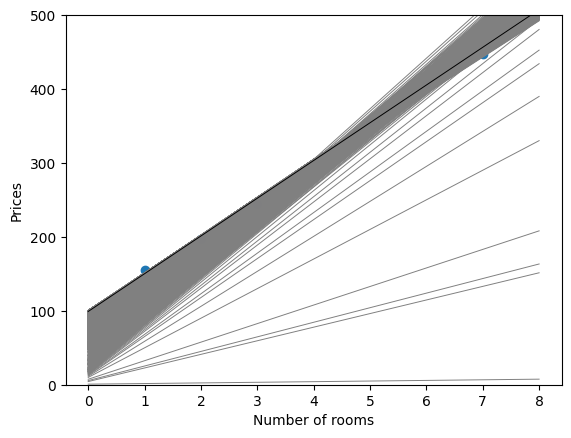

In [8]:
def linear_regression(features, labels, learning_rate=0.01, epochs=10000):
    # Generates (pseudo) rdm values for the slope and the y-intercept
    price_per_room = random.random()    
    base_price = random.random()
    # Repeats the update step many times
    for epoch in range(epochs):
        if True:
            draw_line(price_per_room, base_price, starting=0, ending=8)
        i = random.randint(0, len(features)-1) # Picks a random point on our dataset
        num_rooms = features[i]
        price = labels[i]

        # Applies the square trick to move the line closer to our point
        price_per_room, base_price = square_trick(base_price, 
                                                  price_per_room, 
                                                  num_rooms, 
                                                  price, 
                                                  learning_rate=learning_rate)

    draw_line(price_per_room, base_price, "black", starting=0, ending=8)
    plot_points(features, labels)
    print("Price per room: ", price_per_room)
    print("Base price: ", base_price)

    return price_per_room, base_price

# This line is for the x-axis to appear in the figure
plt.ylim(0, 500)

linear_regression(features, labels, learning_rate=0.01, epochs=10000)  